# Team Vansh HERC 2027: analysis walkthrough

Condensed, executed walkthrough of the six analyses behind the proposal. The single-script
version is `simulation/terramechanics_analysis.py`; this notebook shows the same steps with
intermediate numbers visible.

**Data:** Apollo 16 Self-Recording Penetrometer, Station 4 (11 to 12 May 1972),
NASA PDS dataset A16L-L-LSRP-2/3-SOIL-MECHANICS-V1.0, via the WUSTL Lunar Data Node.
**Material:** TPU 95A, E = 13.2 MPa (Raise3D Premium TPU-95A TDS, ISO 37).
All random draws use a fixed seed, so every output below is reproducible.

In [1]:
%matplotlib inline
import csv, os, numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# work from the repository root whether the kernel starts here or in notebooks/
ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
os.chdir(ROOT)
print('repo root:', ROOT)

NAVY = '#0B3D91'; GOLD = '#E87D1E'; GRAY = '#6E6E6E'
plt.rcParams.update({'font.size': 10, 'axes.grid': True, 'grid.color': '#D9DDE3'})

def load_srp(path):
    with open(path, newline='') as fh:
        rows = list(csv.reader(fh))
    for i, r in enumerate(rows):
        if any('Load (N)' == c.strip() for c in r):
            hdr = [c.strip() for c in r]; break
    i_load = hdr.index('Load (N)'); i_str = hdr.index('Stress (N / cm2)')
    i_dep  = hdr.index('Actual Penetration Depth (cm)')
    pts = []
    for r in rows[i + 1:]:
        try: pts.append((float(r[i_dep]), float(r[i_load]), float(r[i_str])))
        except (ValueError, IndexError): pass
    d = np.array([p[0] for p in pts]); F = np.array([p[1] for p in pts])
    return d, F, d * 0 + F / np.maximum(d, 1e-9) * 0, np.array([p[2] for p in pts])

tests = {}
for idx in (5, 6, 7, 8):
    d, F, _, s = load_srp(f'data/a16_index{idx}.csv')
    tests[idx] = (d, s)
    print(f'a16_index{idx}.csv: {len(d)} points, depth {d.min():.2f} to {d.max():.2f} cm')

repo root: /home/user/teamvansh-repo
a16_index5.csv: 25 points, depth 0.00 to 21.60 cm
a16_index6.csv: 28 points, depth 0.00 to 74.20 cm
a16_index7.csv: 19 points, depth 0.00 to 45.40 cm
a16_index8.csv: 37 points, depth 0.00 to 72.90 cm


In [2]:
# Analysis 2: Bekker pressure-sinkage fits, p = k * z^n (stress converted N/cm2 -> kPa)
print(f"{'run':>6} {'k (kPa cm^-n)':>14} {'n':>6} {'R2 (log space)':>15}")
ks, ns = [], []
for idx in (6, 7, 8):
    z, p = tests[idx][0], tests[idx][1] * 10.0
    m = (z > 0.5) & (p > 0)
    x, y = np.log(z[m]), np.log(p[m])
    n, lnk = np.polyfit(x, y, 1)
    r2 = 1 - ((y - (lnk + n*x))**2).sum() / ((y - y.mean())**2).sum()
    ks.append(np.exp(lnk)); ns.append(n)
    print(f"{idx:>6} {np.exp(lnk):>14.1f} {n:>6.2f} {r2:>15.2f}")
print(f"{'mean':>6} {np.mean(ks):>14.1f} {np.mean(ns):>6.2f}")
print()
print('R2 in log space is modest (0.10 to 0.24) because the SRP points scatter; the')
print('robust takeaway is n < 1: the soil hardens with depth, so static sinkage stays')
print('small and the mass budget goes to traction adaptivity (the Camel Wheel).')

   run  k (kPa cm^-n)      n  R2 (log space)
     6           29.6   0.61            0.24
     7           51.8   0.70            0.18
     8          158.1   0.41            0.10
  mean           79.8   0.57

R2 in log space is modest (0.10 to 0.24) because the SRP points scatter; the
robust takeaway is n < 1: the soil hardens with depth, so static sinkage stays
small and the mass budget goes to traction adaptivity (the Camel Wheel).


trained beta = [-3.1406, 7.2035, -2.9114]
AUC = 0.990 | accuracy at 0.5 = 95.5% | missed = 98 | false alarms = 82


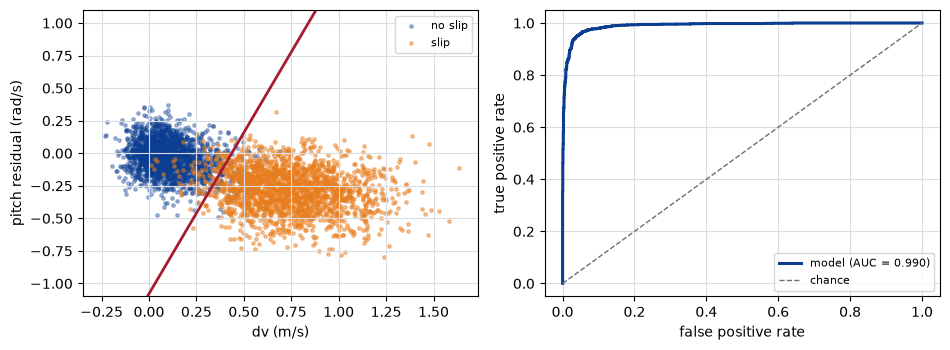

In [3]:
# Analysis 5: wheel-slip detection, physics-informed synthetic set + logistic regression
rng = np.random.default_rng(42)
N = 4000
slip = rng.integers(0, 2, N)
true_slip = np.clip(rng.normal(0.75 * slip + 0.05, 0.18), 0, 1)
dv = true_slip * rng.normal(0.9, 0.22, N) + rng.normal(0.02, 0.08, N)      # wheel-body mismatch, m/s
pitch = -0.35 * true_slip * rng.normal(1, 0.3, N) + rng.normal(0, 0.12, N) # pitch-rate residual, rad/s
X = np.column_stack([np.ones(N), dv, pitch]); y = slip.astype(float)
beta = np.zeros(3)
for _ in range(600):
    p = 1 / (1 + np.exp(-X @ beta))
    beta += 0.35 * X.T @ (y - p) / N
scores = 1 / (1 + np.exp(-X @ beta))
order = np.argsort(-scores); tps = np.cumsum(y[order]); fps = np.cumsum(1 - y[order])
auc = np.trapezoid(tps / tps[-1], fps / fps[-1])
pred = (scores >= 0.5).astype(int)
acc = (pred == slip).mean()
print(f'trained beta = [{beta[0]:.4f}, {beta[1]:.4f}, {beta[2]:.4f}]')
print(f'AUC = {auc:.3f} | accuracy at 0.5 = {acc:.1%} | missed = {(pred < slip).sum()} | false alarms = {(pred > slip).sum()}')

fig, axs = plt.subplots(1, 2, figsize=(9.6, 3.6))
axs[0].scatter(dv[y == 0], pitch[y == 0], s=6, c=NAVY, alpha=0.35, label='no slip')
axs[0].scatter(dv[y == 1], pitch[y == 1], s=6, c=GOLD, alpha=0.45, label='slip')
xx, yy = np.meshgrid(np.linspace(-0.35, 1.6, 200), np.linspace(-1.1, 1.1, 200))
axs[0].contour(xx, yy, 1 / (1 + np.exp(-(beta[0] + beta[1]*xx + beta[2]*yy))), levels=[0.5], colors=['#A51C30'], linewidths=2)
axs[0].set_xlabel('dv (m/s)'); axs[0].set_ylabel('pitch residual (rad/s)'); axs[0].legend(fontsize=8)
axs[1].plot(fps / fps[-1], tps / tps[-1], color=NAVY, lw=2.2, label=f'model (AUC = {auc:.3f})')
axs[1].plot([0, 1], [0, 1], color=GRAY, lw=1, ls='--', label='chance')
axs[1].set_xlabel('false positive rate'); axs[1].set_ylabel('true positive rate'); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [4]:
# Analysis 6: lunar-gravity power budget over the 66 m mock course (condensed recheck)
seg = [(0, 6, 0), (6, 14, 10), (14, 22, 20), (22, 30, 20), (30, 38, -5), (38, 50, 0), (50, 58, 10), (58, 66, 0)]
dist = np.linspace(0, 66, 660)
slope = np.piecewise(dist, [(dist >= s) & (dist < e) for s, e, _ in seg], [v for _, _, v in seg])
m_rover, g_moon, r_w = 27.2, 1.62, 0.127
F_wheel = m_rover * g_moon * np.sin(np.radians(slope)) / 4
tau_wheel = F_wheel * r_w
omega = 168 * 2 * np.pi / 60        # 10-inch wheel at the 168 rpm cap
eta = 0.6
P_motor = np.abs(tau_wheel) * omega / eta + 6
I_bus = P_motor * 4 / 24 + 0.25     # 4 motors on a 24 V bus + 0.25 A fixed
Ah_pack = 10.0                      # 6S2P, 22.2 V, 10 Ah
dt = (dist[1] - dist[0]) / 0.35     # seconds per step at 0.35 m/s
soc = 100 - np.cumsum(I_bus * dt) / 3600 / Ah_pack * 100
print(f'peak bus current: {I_bus.max():.2f} A (on the 20 deg climbs)')
print(f'flat-running bus current: about {I_bus[slope == 0].mean():.2f} A')
print(f'SOC at course end: {soc[-1]:.1f}%')

peak bus current: 3.59 A (on the 20 deg climbs)
flat-running bus current: about 1.25 A
SOC at course end: 98.9%


## From notebook to onboard

The trained coefficients above deploy directly in `firmware/rover_firmware.ino` as a fixed
threshold, evaluated every control tick on the XIAO ESP32S3:

```
SLIP_B0 = -3.1406f;  SLIP_B1 = 7.2035f;  SLIP_B2 = -2.9114f;
p_slip = 1 / (1 + exp(-(B0 + B1*dv + B2*pitchRes)));
slip if p_slip >= 0.5, re-engage below 0.35
```

Power budget peaks on the 20 degree climbs, which is where the slip gate matters most.